In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns",None)

In [3]:
sns.set_style("whitegrid")

In [4]:
df=pd.read_csv("german_credit_data.csv")

In [5]:
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


In [6]:
df["Age"].describe()

count    1000.000000
mean       35.546000
std        11.375469
min        19.000000
25%        27.000000
50%        33.000000
75%        42.000000
max        75.000000
Name: Age, dtype: float64

In [7]:
df["Risk"].value_counts()

Risk
good    700
bad     300
Name: count, dtype: int64

In [8]:
df.shape

(1000, 11)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0        1000 non-null   int64
 1   Age               1000 non-null   int64
 2   Sex               1000 non-null   str  
 3   Job               1000 non-null   int64
 4   Housing           1000 non-null   str  
 5   Saving accounts   817 non-null    str  
 6   Checking account  606 non-null    str  
 7   Credit amount     1000 non-null   int64
 8   Duration          1000 non-null   int64
 9   Purpose           1000 non-null   str  
 10  Risk              1000 non-null   str  
dtypes: int64(5), str(6)
memory usage: 115.1 KB


In [10]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,1000.0,NaN,NaN,NaN,499.5,288.819436,0.0,249.75,499.5,749.25,999.0
Age,1000.0,NaN,NaN,NaN,35.546,11.375469,19.0,27.0,33.0,42.0,75.0
Sex,1000,2,male,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job,1000.0,NaN,NaN,NaN,1.904,0.653614,0.0,2.0,2.0,2.0,3.0
Housing,1000,3,own,713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Saving accounts,817,4,little,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Checking account,606,3,little,274,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
Purpose,1000,8,car,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
df["Job"].unique()

array([2, 1, 3, 0])

In [12]:
df.isna().sum()

Unnamed: 0            0
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:

# Preserve records and handle missing categorical values
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

df["Saving accounts"] = df["Saving accounts"].fillna("unknown")
df["Checking account"] = df["Checking account"].fillna("unknown")

df = df.reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nRisk distribution:")
print(df["Risk"].value_counts())


Shape after cleaning: (1000, 10)

Missing values:
Age                 0
Sex                 0
Job                 0
Housing             0
Saving accounts     0
Checking account    0
Credit amount       0
Duration            0
Purpose             0
Risk                0
dtype: int64

Risk distribution:
Risk
good    700
bad     300
Name: count, dtype: int64


In [15]:
df

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,unknown,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,unknown,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad
...,...,...,...,...,...,...,...,...,...,...
995,31,female,1,own,little,unknown,1736,12,furniture/equipment,good
996,40,male,3,own,little,little,3857,30,car,good
997,38,male,2,own,little,unknown,804,12,radio/TV,good
998,23,male,2,free,little,little,1845,45,radio/TV,bad


In [16]:
df.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account',
       'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='str')

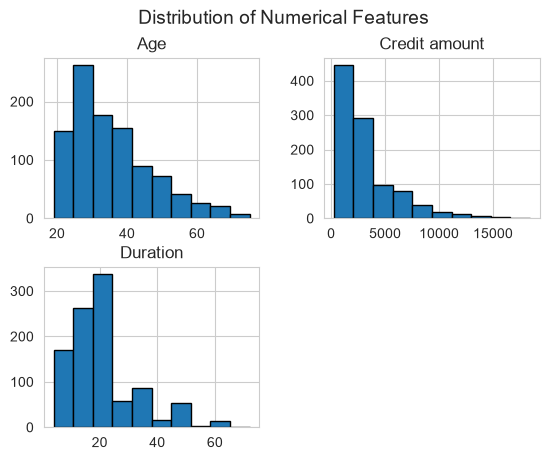

In [17]:
df[["Age","Credit amount","Duration"]].hist(bins=10,edgecolor="black")
plt.suptitle("Distribution of Numerical Features",fontsize=14)
plt.show()

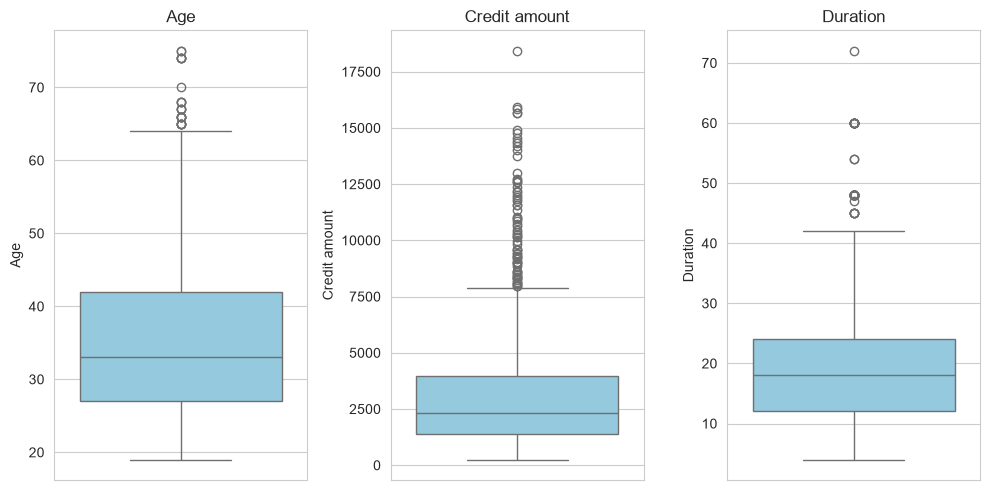

In [18]:
plt.figure(figsize=(10,5))
for i,col in enumerate (["Age","Credit amount","Duration"]):
    plt.subplot(1,3,i+1)
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(col)
    
plt.tight_layout()
plt.show()
    

In [19]:
df.query("Duration >=60")

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
29,63,male,2,own,little,little,6836,60,business,bad
134,21,female,2,own,moderate,unknown,10144,60,radio/TV,good
255,27,male,1,own,unknown,moderate,7418,60,radio/TV,good
332,24,female,3,own,moderate,moderate,7408,60,car,bad
373,63,male,3,free,unknown,unknown,13756,60,car,good
374,60,female,3,free,moderate,moderate,14782,60,vacation/others,bad
616,27,male,3,free,unknown,moderate,9157,60,radio/TV,good
637,21,male,2,own,little,unknown,15653,60,radio/TV,good
672,42,male,3,own,little,unknown,10366,60,car,good
677,24,male,2,own,moderate,moderate,5595,72,radio/TV,bad


In [20]:
categorical_cols=["Sex","Job","Housing","Saving accounts","Checking account","Purpose"]

C:\Users\vibha\AppData\Local\Temp\ipykernel_17180\303826341.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data =df, x=col, palette="Set2",order=df[col].value_counts().index)
C:\Users\vibha\AppData\Local\Temp\ipykernel_17180\303826341.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data =df, x=col, palette="Set2",order=df[col].value_counts().index)
C:\Users\vibha\AppData\Local\Temp\ipykernel_17180\303826341.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data =df, x=col, palette="Set2",order=df[col].value_counts().index)
C

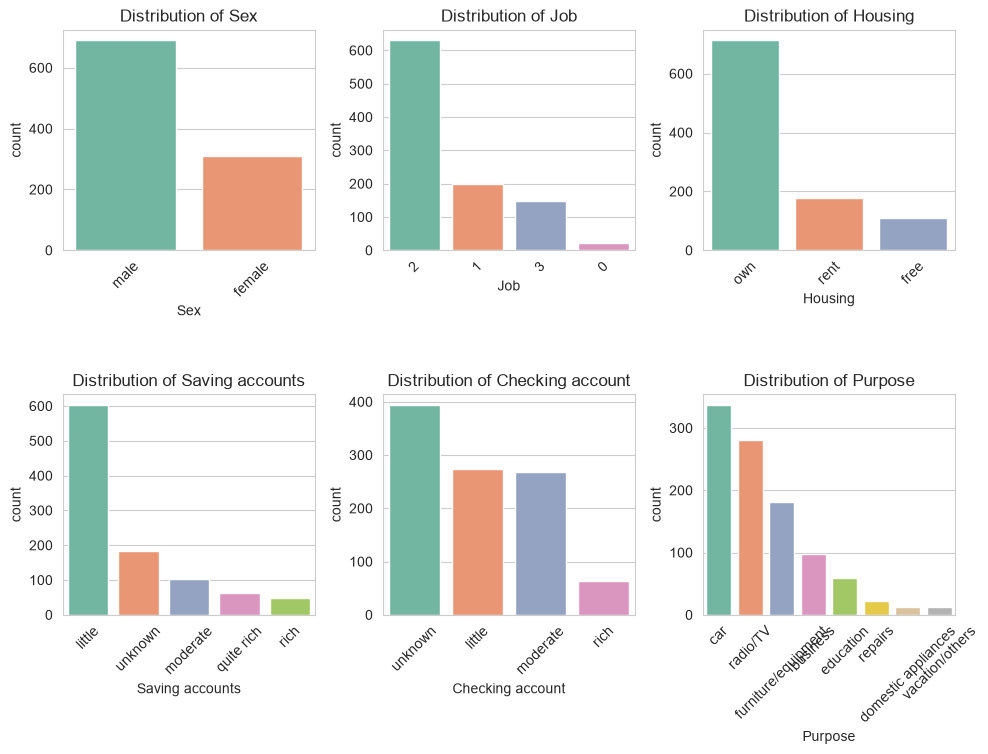

In [21]:
plt.figure(figsize=(10,10))
for i, col in enumerate(categorical_cols):
    plt.subplot(3,3,i+1)
    sns.countplot(data =df, x=col, palette="Set2",order=df[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    
plt.tight_layout()
plt.show()

In [22]:
corr=df[["Age","Job","Credit amount","Duration"]].corr()

In [23]:
corr

,Age,Job,Credit amount,Duration
Age,1.000000,0.015673,0.032716,-0.036136
Job,0.015673,1.000000,0.285385,0.210910
Credit amount,0.032716,0.285385,1.000000,0.624984
Duration,-0.036136,0.210910,0.624984,1.000000


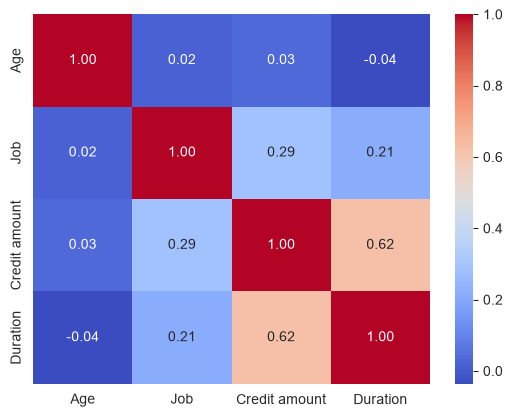

In [24]:
sns.heatmap(corr, annot=True,cmap="coolwarm",fmt=".2f")
plt.show()

In [25]:
df.groupby("Job")["Credit amount"].mean()

Job
0    2745.136364
1    2358.520000
2    3070.965079
3    5435.493243
Name: Credit amount, dtype: float64

In [26]:
df.groupby("Sex")["Credit amount"].mean()

Sex
female    2877.774194
male      3448.040580
Name: Credit amount, dtype: float64

In [27]:
pd.pivot_table(df, values="Credit amount",index="Housing",columns="Purpose")

Purpose,business,car,domestic appliances,education,furniture/equipment,radio/TV,repairs,vacation/others
Housing,,,,,,,,
free,4931.800000,5834.181818,NaN,4387.266667,4100.181818,2417.333333,2750.666667,7227.250
own,3800.592105,3329.949772,1546.5,2198.647059,3107.459016,2540.493392,2866.000000,8700.375
rent,5614.125000,3487.968254,1255.5,2931.000000,2727.354167,2199.763158,1522.000000,NaN


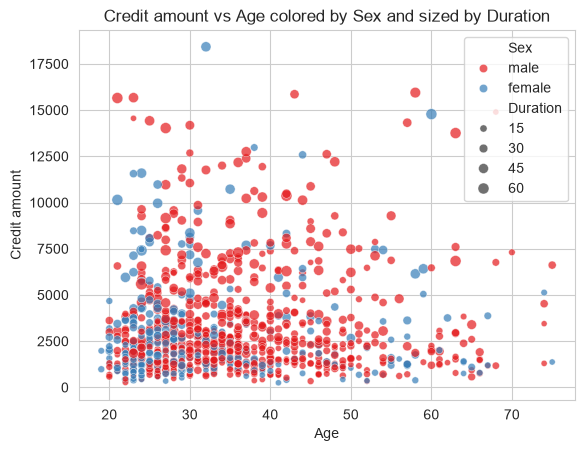

In [28]:
sns.scatterplot(data =df, x="Age", y="Credit amount",hue="Sex", size="Duration",alpha=0.7,palette="Set1")
plt.title("Credit amount vs Age colored by Sex and sized by Duration")
plt.show()

C:\Users\vibha\AppData\Local\Temp\ipykernel_17180\1343808294.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data =df, x="Saving accounts", y="Credit amount",palette="Pastel1")


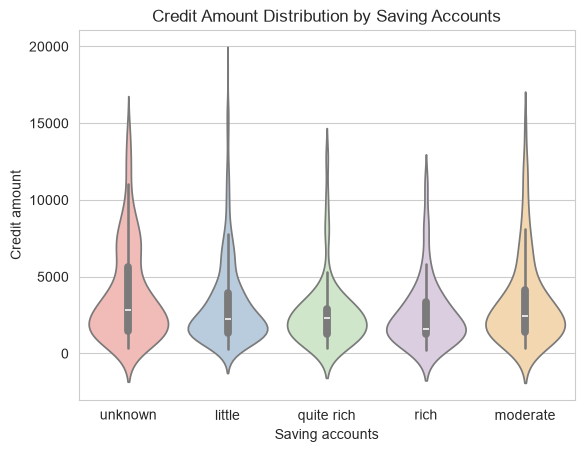

In [29]:
sns.violinplot(data =df, x="Saving accounts", y="Credit amount",palette="Pastel1")
plt.title("Credit Amount Distribution by Saving Accounts")
plt.show()

In [30]:
df["Risk"].value_counts(normalize=True)*100

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64

C:\Users\vibha\AppData\Local\Temp\ipykernel_17180\1998490026.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Risk",y=col, palette ="Pastel2")
C:\Users\vibha\AppData\Local\Temp\ipykernel_17180\1998490026.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Risk",y=col, palette ="Pastel2")
C:\Users\vibha\AppData\Local\Temp\ipykernel_17180\1998490026.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Risk",y=col, palette ="Pastel2")


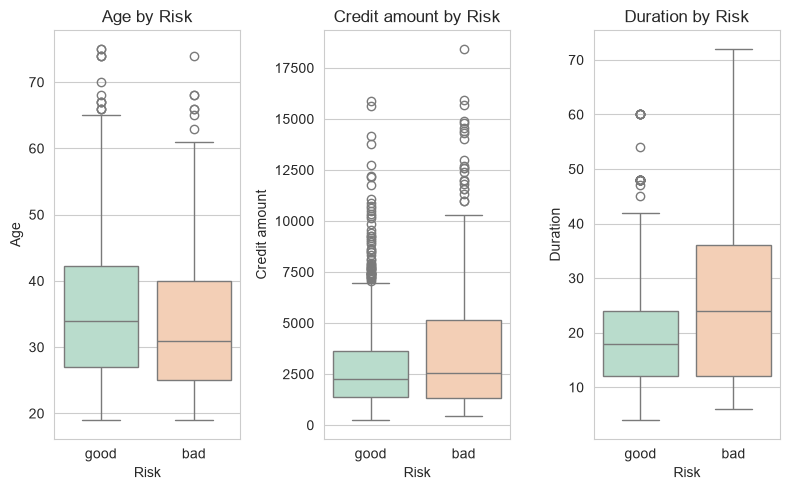

In [31]:
plt.figure(figsize=(8,5))
for i,col in enumerate(["Age","Credit amount","Duration"]):
    plt.subplot(1,3,i+1)
    sns.boxplot(data=df, x="Risk",y=col, palette ="Pastel2")
    plt.title(f"{col} by Risk")
    
plt.tight_layout()
plt.show()

In [32]:
df.groupby("Risk")[["Age","Credit amount","Duration"]].mean()

,Age,Credit amount,Duration
Risk,,,
bad,33.963333,3938.126667,24.860000
good,36.224286,2985.457143,19.207143


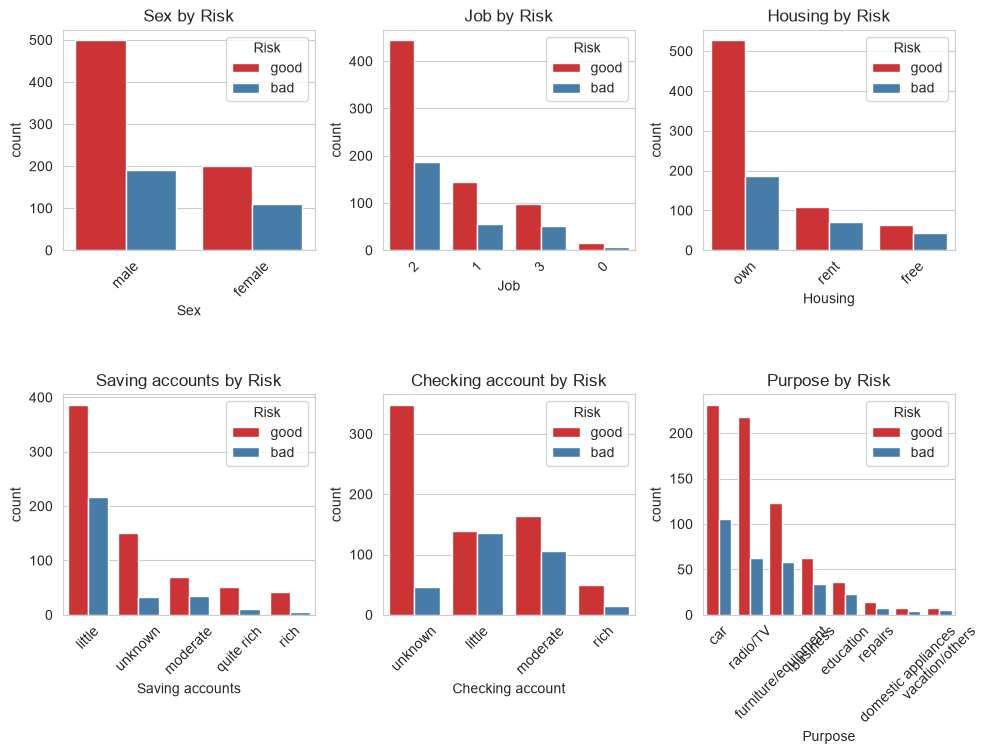

In [33]:
plt.figure(figsize=(10,10))
for i, col in enumerate(categorical_cols):
    plt.subplot(3,3,i+1)
    sns.countplot(data=df,x=col, hue="Risk",palette="Set1",order=df[col].value_counts().index)
    plt.title(f"{col} by Risk")
    plt.xticks(rotation=45)
    
plt.tight_layout()
plt.show()

In [34]:
features=["Age","Sex","Job","Housing","Saving accounts","Checking account","Credit amount","Duration"]

In [35]:
target="Risk"

In [36]:
df_model=df[features + [target]].copy()

In [37]:
df_model.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Risk
0,67,male,2,own,unknown,little,1169,6,good
1,22,female,2,own,little,moderate,5951,48,bad
2,49,male,1,own,little,unknown,2096,12,good
3,45,male,2,free,little,little,7882,42,good
4,53,male,2,free,little,little,4870,24,bad


In [38]:
from sklearn.preprocessing import LabelEncoder
import joblib

In [39]:
cat_cols=df_model.select_dtypes(include="object").columns.drop("Risk")

C:\Users\vibha\AppData\Local\Temp\ipykernel_17180\2637306855.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols=df_model.select_dtypes(include="object").columns.drop("Risk")


In [40]:
le_dict={}

In [41]:
cat_cols

Index(['Sex', 'Housing', 'Saving accounts', 'Checking account'], dtype='str')

In [42]:
for col in cat_cols:
    le=LabelEncoder()
    df_model[col]=le.fit_transform(df_model[col])
    le_dict[col]=le
    joblib.dump(le, f"{col}_encoder.pkl")

In [43]:
le_target = LabelEncoder()

In [44]:
df_model[target]=le_target.fit_transform(df_model[target])

In [45]:
df_model[target].value_counts()

Risk
1    700
0    300
Name: count, dtype: int64

In [46]:
joblib.dump(le_target, "target_encoder.pkl")

['target_encoder.pkl']

In [47]:
df_model.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Risk
0,67,1,2,1,4,0,1169,6,1
1,22,0,2,1,0,1,5951,48,0
2,49,1,1,1,0,3,2096,12,1
3,45,1,2,0,0,0,7882,42,1
4,53,1,2,0,0,0,4870,24,0


In [48]:
from sklearn.model_selection import train_test_split

In [49]:
x=df_model.drop(target, axis=1)

In [50]:
y=df_model[target]

In [51]:
x


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration
0,67,1,2,1,4,0,1169,6
1,22,0,2,1,0,1,5951,48
2,49,1,1,1,0,3,2096,12
3,45,1,2,0,0,0,7882,42
4,53,1,2,0,0,0,4870,24
...,...,...,...,...,...,...,...,...
995,31,0,1,1,0,3,1736,12
996,40,1,3,1,0,0,3857,30
997,38,1,2,1,0,3,804,12
998,23,1,2,0,0,0,1845,45


In [52]:
y

0      1
1      0
2      1
3      1
4      0
      ..
995    1
996    1
997    1
998    0
999    1
Name: Risk, Length: 1000, dtype: int64

In [53]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify =y,random_state=1)

In [54]:
X_train.shape

(800, 8)

In [55]:
X_test.shape

(200, 8)

In [56]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

In [57]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score

def train_model(model, param_grid, X_train, y_train, X_test, y_test):
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=1
    )

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    return best_model, acc, grid.best_params_


In [58]:
dt=DecisionTreeClassifier(random_state=1, class_weight="balanced")
dt_param_grid={
    "max_depth" : [3,5,7,10, None],
    "min_samples_split": [2,5,10],
    "min_samples_leaf" : [1,2,4]
}

In [59]:
best_dt, acc_dt, params_dt = train_model(dt, dt_param_grid, X_train, y_train, X_test, y_test)


In [60]:
print("Decision Tree Accuracy", acc_dt)

Decision Tree Accuracy 0.7


In [61]:
print("Best parameters", params_dt)

Best parameters {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [62]:
rf=RandomForestClassifier(random_state=1,class_weight="balanced", n_jobs=-1)

In [63]:
rf_param_grid={
    "n_estimators": [100,200],
    "max_depth": [ 5, 7, 10, None],
    "min_samples_split" : [2,5,10],
    "min_samples_leaf": [1,2,4]
}

In [64]:
best_rf, acc_rf, params_rf = train_model(rf, rf_param_grid, X_train, y_train, X_test, y_test)


In [65]:
print("Random Forest Accuracy", acc_rf)

Random Forest Accuracy 0.745


In [66]:
print("Best params", params_rf)

Best params {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}


In [67]:
et= ExtraTreesClassifier(random_state= 1, class_weight="balanced", n_jobs=-1)

In [68]:
et_param_grid={
    "n_estimators": [100,200],
    "max_depth": [ 5, 7, 10, None],
    "min_samples_split" : [2,5,10],
    "min_samples_leaf": [1,2,4]
}

In [69]:
best_et, acc_et, params_et = train_model(et, et_param_grid, X_train, y_train, X_test, y_test)


In [70]:
print("Extra trees accuracy", acc_et)

Extra trees accuracy 0.74


In [71]:
print("Best params:" , params_et)

Best params: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}


In [72]:

from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=1,
    eval_metric="logloss"
)


In [73]:
xgb_param_grid={
    "n_estimators": [100,200],
    "max_depth": [3,5,7],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.7,1],
    "colsample_bytree": [0.7,1]
}

In [74]:
best_xgb, acc_xgb, params_xgb=train_model(xgb, xgb_param_grid, X_train, y_train, X_test, y_test)

In [75]:
print("XGB accuracy", acc_xgb)

XGB accuracy 0.785


In [76]:
print("Best params",params_xgb)

Best params {'colsample_bytree': 1, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.7}


In [77]:
joblib.dump(best_xgb,"xg_boost_credit_model.pkl")

['xg_boost_credit_model.pkl']

In [78]:

from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

# Predict on test data
y_pred = best_xgb.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# Summary: TP, FN, FP, TN
tn, fp, fn, tp = cm.ravel()

summary = pd.DataFrame({
    "Count": [tp, fn, fp, tn]
}, index=[
    "True Positive (TP)",
    "False Negative (FN)",
    "False Positive (FP)",
    "True Negative (TN)"
])

print("\nConfusion Matrix Summary:")
print(summary)

# Precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))


Confusion Matrix:
[[ 28  32]
 [ 11 129]]

Confusion Matrix Summary:
                     Count
True Positive (TP)     129
False Negative (FN)     11
False Positive (FP)     32
True Negative (TN)      28

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.47      0.57        60
           1       0.80      0.92      0.86       140

    accuracy                           0.79       200
   macro avg       0.76      0.69      0.71       200
weighted avg       0.78      0.79      0.77       200



In [79]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Decision Tree": best_dt,
    "Random Forest": best_rf,
    "Extra Trees": best_et,
    "XGBoost": best_xgb
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))


           Model  Accuracy  Precision  Recall  F1-Score
0  Decision Tree     0.700      0.828   0.721     0.771
1  Random Forest     0.745      0.825   0.807     0.816
2    Extra Trees     0.740      0.814   0.814     0.814
3        XGBoost     0.785      0.801   0.921     0.857


In [80]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, make_scorer, f1_score
from xgboost import XGBClassifier

# Focus on detecting bad-credit cases (class 0)
bad_credit_f1 = make_scorer(
    f1_score,
    pos_label=0,
    zero_division=0
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_bad = GridSearchCV(
    xgb_model,
    param_grid,
    scoring=bad_credit_f1,
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search_bad.fit(X_train, y_train)

best_xgb_bad = grid_search_bad.best_estimator_
y_pred_bad = best_xgb_bad.predict(X_test)

print("Best Parameters:")
print(grid_search_bad.best_params_)

print("\nCross-validation F1 for bad-credit class:")
print(round(grid_search_bad.best_score_, 3))

print("\nTest Accuracy:")
print(round(accuracy_score(y_test, y_pred_bad), 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_bad,
    zero_division=0
))


Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200, 'subsample': 0.8}

Cross-validation F1 for bad-credit class:
0.514

Test Accuracy:
0.79

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.48      0.58        60
           1       0.81      0.92      0.86       140

    accuracy                           0.79       200
   macro avg       0.77      0.70      0.72       200
weighted avg       0.78      0.79      0.78       200



In [81]:

from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score

# Give bad-credit cases more weight
sample_weights = compute_sample_weight(
    class_weight={0: 1.5, 1: 1.0},
    y=y_train
)

weighted_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

weighted_xgb.fit(X_train, y_train, sample_weight=sample_weights)

y_pred_weighted = weighted_xgb.predict(X_test)

print("Test Accuracy:", round(
    accuracy_score(y_test, y_pred_weighted), 3
))

print(classification_report(
    y_test, y_pred_weighted, zero_division=0
))


Test Accuracy: 0.765
              precision    recall  f1-score   support

           0       0.62      0.55      0.58        60
           1       0.82      0.86      0.84       140

    accuracy                           0.77       200
   macro avg       0.72      0.70      0.71       200
weighted avg       0.76      0.77      0.76       200



In [82]:

from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, f1_score
)

# Search for a balanced model
param_dist = {
    "n_estimators": [100, 150, 200, 300, 400],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "reg_lambda": [1, 3, 5, 10]
}

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=40,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Tune using training data only
search.fit(X_train, y_train)

best_balanced_xgb = search.best_estimator_

print("Best parameters:", search.best_params_)
print("CV macro F1:", round(search.best_score_, 3))

# Evaluate on test data
y_pred = best_balanced_xgb.predict(X_test)

print("Test accuracy:",
      round(accuracy_score(y_test, y_pred), 3))
print("Test macro F1:",
      round(f1_score(y_test, y_pred, average="macro"), 3))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best parameters: {'subsample': 1.0, 'reg_lambda': 3, 'n_estimators': 150, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.9}
CV macro F1: 0.665
Test accuracy: 0.795
Test macro F1: 0.728

Classification report:
              precision    recall  f1-score   support

           0       0.73      0.50      0.59        60
           1       0.81      0.92      0.86       140

    accuracy                           0.80       200
   macro avg       0.77      0.71      0.73       200
weighted avg       0.79      0.80      0.78       200

Confusion matrix:
[[ 30  30]
 [ 11 129]]
